accuracy: 0.7474402730375427
precision (macro): 0.7388870839889982
recall (macro): 0.7443020959157592
f1-score (macro): 0.7376434336529322
scor mediu f1 cu k=5: 0.7314855303242359
scor mediu f1 cu k=10: 0.7350157336608829


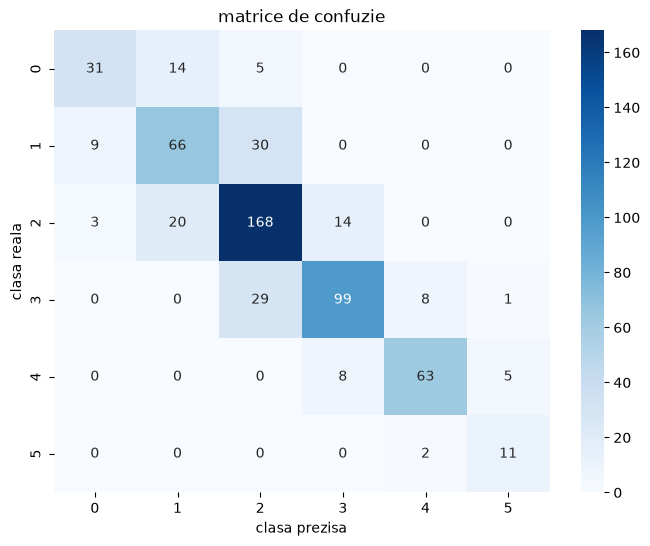

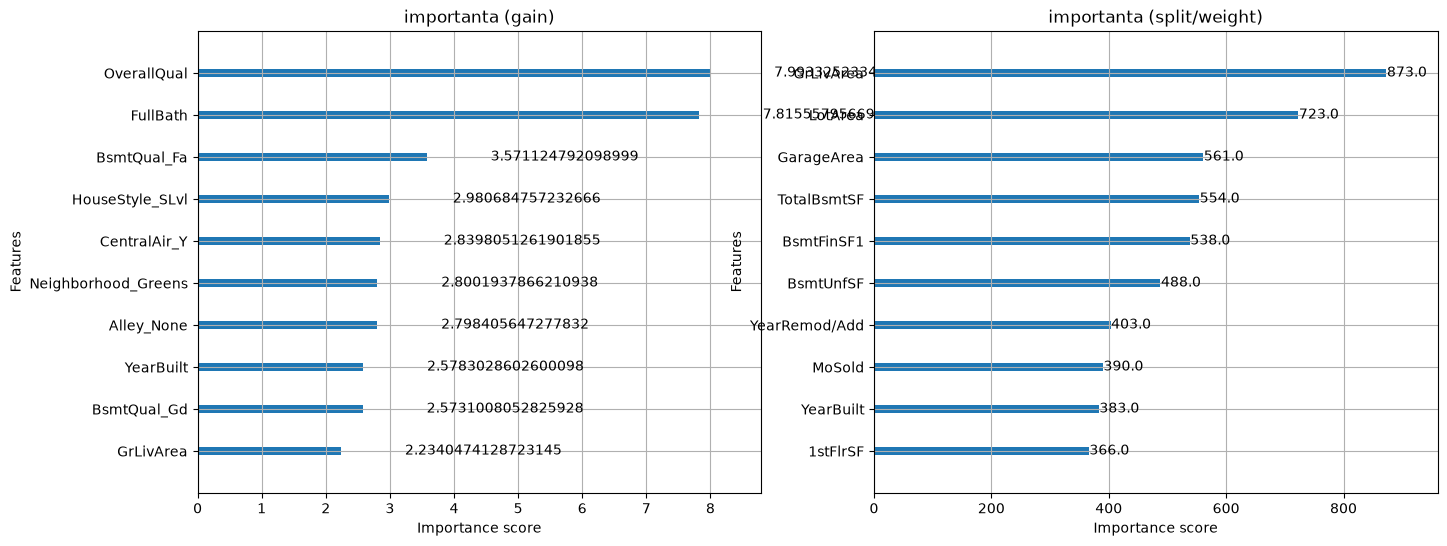

[I 2026-11-04 22:02:28,255] A new study created in memory with name: no-name-9da26500-c67e-42b1-97c6-15c44516298e
[I 2026-11-04 22:02:35,123] Trial 0 finished with value: 0.7224221471416747 and parameters: {'max_depth': 5, 'learning_rate': 0.19063571821788408, 'n_estimators': 160}. Best is trial 0 with value: 0.7224221471416747.
[I 2026-11-04 22:02:38,935] Trial 1 finished with value: 0.6976639236844681 and parameters: {'max_depth': 6, 'learning_rate': 0.039643541684062936, 'n_estimators': 73}. Best is trial 0 with value: 0.7224221471416747.
[I 2026-11-04 22:02:43,373] Trial 2 finished with value: 0.71791896564139 and parameters: {'max_depth': 3, 'learning_rate': 0.1745734676972377, 'n_estimators': 140}. Best is trial 0 with value: 0.7224221471416747.
[I 2026-11-04 22:02:54,175] Trial 3 finished with value: 0.6964252738959561 and parameters: {'max_depth': 7, 'learning_rate': 0.013911053916202464, 'n_estimators': 196}. Best is trial 0 with value: 0.7224221471416747.
[I 2026-11-04 22:02:

cei mai buni parametri gasiti de optuna: {'max_depth': 6, 'learning_rate': 0.12255876808378806, 'n_estimators': 57}


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix
import xgboost as xgb
import optuna

# incarcam datele
housing = pd.read_csv('AmesHousing.csv', sep='\t')
housing.columns = housing.columns.str.replace(' ', '').str.replace('_', '')

# organizam datele
num_cols = housing.select_dtypes(include=np.number).columns
cat_cols = housing.select_dtypes(exclude=np.number).columns

# reparam datele lipsa 
housing[num_cols] = housing[num_cols].fillna(housing[num_cols].median())
housing[cat_cols] = housing[cat_cols].fillna("None")

# transformam pretul in cele 6 clase
bins = [0, 100000, 130000, 180000, 250000, 400000, np.inf]
labels = [0, 1, 2, 3, 4, 5]
housing['PriceClass'] = pd.cut(housing['SalePrice'], bins=bins, labels=labels)

# pregatim x si y
# scoatem pretul exact si identificatorii ca modelul sa nu triseze
y = housing['PriceClass']
X = housing.drop(columns=['SalePrice', 'PriceClass', 'Order', 'PID'])

# transformam tot textul in coloane cu 0 si 1 ca sa le inteleaga xgboost
X = pd.get_dummies(X, drop_first=True)

# facem splitul de 20% cu stratificare pentru clase dezechilibrate
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# setam modelul xgboost multiclass
model = xgb.XGBClassifier(
    objective='multi:softprob',
    num_class=6,
    eval_metric='mlogloss',
    seed=42
)

# antrenam modelul
model.fit(X_train, y_train)

# facem predictii pe test
y_pred = model.predict(X_test)

# printam metricile principale
print("accuracy:", accuracy_score(y_test, y_pred))
print("precision (macro):", precision_score(y_test, y_pred, average='macro'))
print("recall (macro):", recall_score(y_test, y_pred, average='macro'))
print("f1-score (macro):", f1_score(y_test, y_pred, average='macro'))

# testam modelul cu cross validation pe 5 si 10 bucati
cv_5 = cross_val_score(model, X, y, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42), scoring='f1_macro')
print("scor mediu f1 cu k=5:", cv_5.mean())

cv_10 = cross_val_score(model, X, y, cv=StratifiedKFold(n_splits=10, shuffle=True, random_state=42), scoring='f1_macro')
print("scor mediu f1 cu k=10:", cv_10.mean())

# desenam matricea de confuzie
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('matrice de confuzie')
plt.ylabel('clasa reala')
plt.xlabel('clasa prezisa')
plt.show()

# desenam importanta atributelor dupa gain si dupa split
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
xgb.plot_importance(model, importance_type='gain', max_num_features=10, ax=ax[0], title='importanta (gain)')
xgb.plot_importance(model, importance_type='weight', max_num_features=10, ax=ax[1], title='importanta (split/weight)')
plt.show()

# partea de optuna cu tpesampler ca sa gaseasca automat cei mai buni parametri
def objective(trial):
    # ii dam cateva valori sa aleaga din ele
    param = {
        'objective': 'multi:softprob',
        'num_class': 6,
        'eval_metric': 'mlogloss',
        'max_depth': trial.suggest_int('max_depth', 3, 8),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2),
        'n_estimators': trial.suggest_int('n_estimators', 50, 200),
        'seed': 42
    }
    
    # cream modelul cu ce a ales
    opt_model = xgb.XGBClassifier(**param)
    
    # ii dam nota in functie de f1 macro
    score = cross_val_score(opt_model, X_train, y_train, cv=3, scoring='f1_macro').mean()
    return score

# ii zicem sa maximizeze scorul
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))

# il lasam sa incerce 10 variante 
study.optimize(objective, n_trials=10)

print("cei mai buni parametri gasiti de optuna:", study.best_params)